# AIDA 2156 Final Project – 01 Data Quality and Missingness

**Data version 2** (`shared/synthetic-data/`), cleaning version 1.1.

**Question:** What is missing, inconsistent, or invalid in the raw onboarding export, does missing information at intake differ by channel or task type, and what does cleaning fix and leave unresolved?

This is step 1 of the final project, which asks where delays and incomplete handoffs appear in the workflow and how reliable those findings are. Knowing which values can be trusted comes first, because every later notebook uses them.

All records are synthetic. Counts and rates describe this simulated dataset, not real employees or real HR performance.

**Use of the answer key.** Cleaning and the descriptive checks in this notebook do not use the answer key (`requests/evaluation_only/`). Section D reports a separately produced evaluation summary that compared the cleaned file with the answer key; that information was never used to make repairs.

In [1]:
import hashlib
import importlib.util
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

# Every value is read as text, so a blank stays a blank ("") and nothing is converted silently
read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
raw = read(SD / "requests/data/requests.csv")                       # system export, recording problems included
cleaned = read(SD / "cleaning/output/requests_cleaned.csv")        # official cleaned requests
events = read(SD / "requests/data/status_events.csv")              # accurate by construction
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


generator = load_module("generator", SD / "requests/generate_requests.py")    # extract time
cleaning = load_module("clean_requests", SD / "cleaning/clean_requests.py")   # allowed category values
EXTRACT_AT = pd.Timestamp(generator.EXTRACT_AT)
ALLOWED = cleaning.ALLOWED

# The cleaned file must be the one made from these exact raw files
sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
fingerprints_match = (sha(SD / "requests/data/requests.csv") == cleaning_info["source_requests_sha256"]
                      and sha(SD / "requests/data/status_events.csv") == cleaning_info["source_events_sha256"]
                      and sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"])

print(f"Data version {DATA_VERSION}; cleaning version {cleaning_info['cleaning_version']}; "
      f"extract {EXTRACT_AT:%Y-%m-%d %H:%M}")
print(f"Raw export: {len(raw):,} rows; cleaned: {len(cleaned):,} requests; status events: {len(events):,}")
print("Cleaned file matches the raw files it was made from:", fingerprints_match)
assert fingerprints_match, "The raw or cleaned files do not match the cleaning record; rerun cleaning/make_cleaned.py"

Data version 2; cleaning version 1.1; extract 2026-09-29 17:00
Raw export: 4,386 rows; cleaned: 4,364 requests; status events: 18,491
Cleaned file matches the raw files it was made from: True


## A. What a blank means

A blank is not automatically an error. In this export a blank can mean five different things:

| Kind of blank | Example | Is it a data problem? |
|:---|:---|:---|
| **Workflow step not reached yet** | No completion time because the team hadn't finished by the extract | No: the value doesn't exist yet |
| **Outcome not yet known** | No readiness result because the task is unfinished and its deadline hasn't passed | No: the outcome can't be known yet, and is never filled in |
| **Missing at intake** | The requester left the start date off the request, so the coordinator had to ask | No: it's part of the workflow being studied (recorded in `info_issue_type`) |
| **Optional** | No requester comment | No |
| **Unexplained** | A missing intake channel | Yes: a recording problem |

Each blank is matched to an explanation using only other recorded fields: the request's status at the extract, whether its information check is complete, its recorded intake issue, and its confirmed start date. Because these are recorded fields rather than certain knowledge, the table reports explanations **supported by recorded fields**.

Unknown readiness (`ready_by_start`) has two separate explanations, kept apart: the task is unfinished and its confirmed deadline is after the extract, or the task is unfinished and its start date has not been confirmed yet. A missing start date is not treated as a future deadline.

Exact duplicate rows are removed first so each request is counted once (duplicates are covered in section C). Task type comes from the cleaned file, because raw task types contain spelling variants.

In [2]:
distinct = raw.drop_duplicates().reset_index(drop=True)
task = distinct["request_id"].map(cleaned.set_index("request_id")["task_type"])
status = distinct["status_at_extract"]
info_done = distinct["info_complete_at"] != ""
gap_at_intake = distinct["info_issue_type"].isin(["missing", "both"])
start = pd.to_datetime(distinct["confirmed_start_date"].replace("", None), format="%Y-%m-%d")
not_finished = distinct["team_completed_at"] == ""
deadline_after_extract = start.notna() & (start + pd.Timedelta(hours=8) > EXTRACT_AT)
start_not_confirmed = start.isna() & ~info_done           # blank start date because the check isn't complete

# For each field: the explanations supported by recorded fields (a blank takes the first one that applies)
NOT_REACHED, UNKNOWN_OUTCOME = "Workflow step not reached yet", "Outcome not yet known"
AT_INTAKE, OPTIONAL = "Missing at intake", "Optional"
explanations = {
    "submitted_hiring_department": [(gap_at_intake, AT_INTAKE)],
    "submitted_start_date": [(gap_at_intake, AT_INTAKE)],
    "equipment_item": [(gap_at_intake & (task == "equipment_setup"), AT_INTAKE)],
    "hiring_department": [(~info_done, NOT_REACHED + ": information check not complete")],
    "confirmed_start_date": [(~info_done, NOT_REACHED + ": information check not complete")],
    "info_complete_at": [(status == "waiting_for_information", NOT_REACHED + ": waiting for information")],
    "assigned_at": [(status.isin(["open", "waiting_for_information"]), NOT_REACHED + ": not assigned")],
    "team_completed_at": [(status != "complete", NOT_REACHED + ": team not finished")],
    "completion_confirmed_at": [(status != "complete", NOT_REACHED + ": not confirmed complete")],
    "ready_by_start": [(not_finished & deadline_after_extract, UNKNOWN_OUTCOME + ": unfinished, deadline after the extract"),
                       (not_finished & start_not_confirmed, UNKNOWN_OUTCOME + ": unfinished, start date not yet confirmed")],
    "requester_comment": [(pd.Series(True, index=distinct.index), OPTIONAL)],
}

rows = []
for field in distinct.columns:
    blank = distinct[field] == ""
    if not blank.any():
        continue
    remaining = blank.copy()
    for rule, explanation in explanations.get(field, []):
        matched = remaining & rule
        if matched.any():
            rows.append({"field": field, "explanation": explanation, "blanks": int(matched.sum())})
        remaining &= ~matched
    if remaining.any():
        rows.append({"field": field, "explanation": "Unexplained (recording problem)", "blanks": int(remaining.sum())})
blanks_by_field = pd.DataFrame(rows)
blanks_by_field.to_csv(OUTPUT_DIR / "blanks_by_field.csv", index=False)
print(f"{len(distinct):,} distinct requests (raw export with exact duplicates removed)")
display(blanks_by_field.set_index(["field", "explanation"]))

unexplained = blanks_by_field[blanks_by_field["explanation"].str.startswith("Unexplained")]
print(f"Unexplained blanks: {unexplained['blanks'].sum()} in {len(unexplained)} fields")

# Both directions: recorded missing information vs a visible blank in a submitted field
visible_gap = ((distinct["submitted_hiring_department"] == "") | (distinct["submitted_start_date"] == "")
               | ((distinct["equipment_item"] == "") & (task == "equipment_setup")))
print(f"Recorded as missing information: {int(gap_at_intake.sum())}; of these with a visible blank: "
      f"{int((gap_at_intake & visible_gap).sum())}")
print(f"Visible blank in a submitted field: {int(visible_gap.sum())}; of these recorded as missing information: "
      f"{int((visible_gap & gap_at_intake).sum())}")

4,364 distinct requests (raw export with exact duplicates removed)


blanks
field                       explanation                                               
submitted_hiring_department Missing at intake                                      146
hiring_department           Workflow step not reached yet: information chec...       1
                            Unexplained (recording problem)                         44
employee_type               Unexplained (recording problem)                         44
intake_channel              Unexplained (recording problem)                         44
submitted_start_date        Missing at intake                                      137
confirmed_start_date        Workflow step not reached yet: information chec...       1
equipment_item              Missing at intake                                       17
requester_comment           Optional                                              3197
info_complete_at            Workflow step not reached yet: waiting for info...       1
assigned_at                 Workflow step not reached yet: not assigned              6
team_completed_at           Workflow step not reached yet: team not finished        45
completion_confirmed_at     Workflow step not reached yet: not confirmed co...      51
ready_by_start              Outcome not yet known: unfinished, deadline aft...      44
                            Outcome not yet known: unfinished, start date n...       1

Unexplained blanks: 132 in 3 fields
Recorded as missing information: 300; of these with a visible blank: 300
Visible blank in a submitted field: 300; of these recorded as missing information: 300


**Reading the table.** Most blanks have an explanation supported by recorded fields. Completion times and confirmed values are blank because those steps hadn't happened by the extract, readiness is blank where the outcome can't be known yet, and the blank submitted fields match requests recorded as missing information at intake, in both directions. Unexplained blanks are confined to three fields: employee type, intake channel, and confirmed hiring department. These are recording problems.

The 45 blank hiring departments in the raw export are one request still waiting for information (its department isn't confirmed yet) plus 44 recording problems.

## B. Does missing information at intake differ by group?

`info_issue_type` records whether a request arrived with required information **missing**, **conflicting**, or **both**. Below, "missing" counts *missing* or *both*, and "conflict" counts *conflict* or *both*, so a request with both is counted in each.

Groups use the cleaned categories. A blank group value stays blank in the cleaned file and is displayed as `unknown` in this analysis: the 44 requests with no recorded channel, and the one request whose department is not yet confirmed. Groups with fewer than 100 requests are marked as small. This is a practical warning that one or two requests noticeably move the rate, not a threshold for reliability.

These are descriptive rates. Several requests belong to the same employee and may share department, start-date, and intake circumstances, so they are not independent. A later notebook will assess uncertainty using resampling that keeps each employee's requests together.

All requests: missing 6.9%, conflict 6.6% of 4,364


,requests,missing,missing_%,conflict,conflict_%,small_group
group,,,,,,
email,1389,129,9.3,93,6.7,False
phone,672,90,13.4,44,6.5,False
unknown,44,2,4.5,0,0.0,True
web_form,2259,79,3.5,150,6.6,False


,requests,missing,missing_%,conflict,conflict_%,small_group
group,,,,,,
equipment_setup,642,42,6.5,28,4.4,False
orientation_scheduling,906,68,7.5,69,7.6,False
payroll_setup,1071,65,6.1,76,7.1,False
system_access,1073,74,6.9,68,6.3,False
workplace_access,672,51,7.6,46,6.8,False


,requests,missing,missing_%,conflict,conflict_%,small_group
group,,,,,,
Administration,614,28,4.6,52,8.5,False
Finance,409,27,6.6,34,8.3,False
Parks,978,68,7.0,62,6.3,False
Recreation,848,55,6.5,40,4.7,False
Transit,889,74,8.3,57,6.4,False
Utilities,625,47,7.5,42,6.7,False
unknown,1,1,100.0,0,0.0,True


,requests,missing,missing_%,conflict,conflict_%,small_group
group,,,,,,
permanent,2324,170,7.3,156,6.7,False
seasonal,1115,73,6.5,68,6.1,False
temporary,925,57,6.2,63,6.8,False


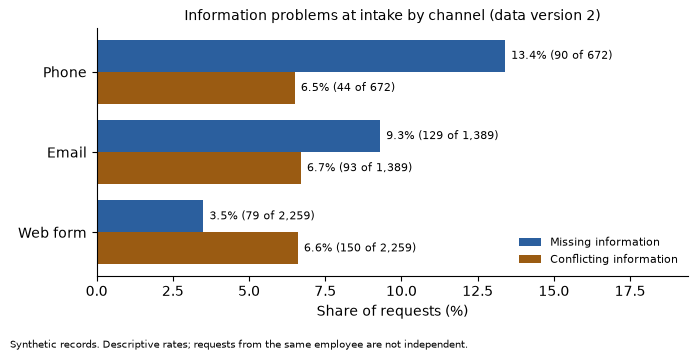

In [3]:
SMALL_GROUP = 100        # practical warning for unstable rates, not a reliability threshold
GROUPS = ["intake_channel", "task_type", "hiring_department", "employee_type"]
issues = cleaned.assign(
    **{g: cleaned[g].replace("", "unknown") for g in GROUPS},
    missing=cleaned["info_issue_type"].isin(["missing", "both"]),
    conflict=cleaned["info_issue_type"].isin(["conflict", "both"]))

tables = []
for group in GROUPS:
    t = issues.groupby(group).agg(requests=("request_id", "size"), missing=("missing", "sum"),
                                  conflict=("conflict", "sum"))
    t["missing_%"] = (100 * t["missing"] / t["requests"]).round(1)
    t["conflict_%"] = (100 * t["conflict"] / t["requests"]).round(1)
    t["small_group"] = t["requests"] < SMALL_GROUP
    tables.append(t.reset_index().rename(columns={group: "group"}).assign(grouped_by=group))
issues_by_group = pd.concat(tables)[["grouped_by", "group", "requests", "missing", "missing_%",
                                     "conflict", "conflict_%", "small_group"]]
issues_by_group.to_csv(OUTPUT_DIR / "intake_issues_by_group.csv", index=False)
overall_missing = 100 * issues["missing"].mean()
overall_conflict = 100 * issues["conflict"].mean()
print(f"All requests: missing {overall_missing:.1f}%, conflict {overall_conflict:.1f}% of {len(issues):,}")
for group, t in issues_by_group.groupby("grouped_by", sort=False):
    display(t.drop(columns="grouped_by").set_index("group"))

# Figure: rates by known channel (the 44 unknown-channel requests are in the table above)
by_channel = issues_by_group[(issues_by_group["grouped_by"] == "intake_channel")
                             & (issues_by_group["group"] != "unknown")].set_index("group")
by_channel = by_channel.loc[["web_form", "email", "phone"]]
fig, ax = plt.subplots(figsize=(7, 3.4))
y = range(len(by_channel))
ax.barh([i + 0.2 for i in y], by_channel["missing_%"], height=0.4, label="Missing information", color="#2b5f9e")
ax.barh([i - 0.2 for i in y], by_channel["conflict_%"], height=0.4, label="Conflicting information", color="#9a5b12")
for i, (name, r) in enumerate(by_channel.iterrows()):
    ax.text(r["missing_%"] + 0.2, i + 0.2, f"{r['missing_%']:.1f}% ({r['missing']} of {r['requests']:,})", va="center", fontsize=8)
    ax.text(r["conflict_%"] + 0.2, i - 0.2, f"{r['conflict_%']:.1f}% ({r['conflict']} of {r['requests']:,})", va="center", fontsize=8)
ax.set_yticks(list(y), ["Web form", "Email", "Phone"])
ax.set_xlabel("Share of requests (%)")
ax.set_xlim(0, max(by_channel["missing_%"].max(), by_channel["conflict_%"].max()) + 6)
ax.set_title("Information problems at intake by channel (data version 2)", fontsize=10)
ax.legend(fontsize=8, loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.04, "Synthetic records. Descriptive rates; requests from the same employee are not independent.", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "intake_issues_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the rates.** Missing information differs most by channel: phone requests were missing information most often and web-form requests least often. Conflicting information is at a similar rate across the three channels. Among groups with at least 100 requests, differences across task type, department and employee type are smaller, about four percentage points at most (the largest is 3.8 points, for conflicts by department). Small groups, such as the one `unknown` department, stay in the tables but are left out of that comparison. A later notebook will assess uncertainty using resampling that keeps each employee's requests together.

The generator sets a different chance of missing information for each channel (see the data card). The observed channel differences are consistent with the generator's settings, so they describe how this simulation behaves, not real intake channels.

In [4]:
# Is the missing intake channel itself concentrated in one group? (44 requests, so counts are small)
channel_blank = distinct.set_index("request_id")["intake_channel"].eq("")
blank_channel = issues.assign(channel_blank=issues["request_id"].map(channel_blank))
rows = []
for group in ["task_type", "hiring_department", "employee_type"]:
    t = blank_channel.groupby(group)["channel_blank"].agg(requests="size", channel_blank="sum")
    t["channel_blank_%"] = (100 * t["channel_blank"] / t["requests"]).round(1)
    rows.append(t.reset_index().rename(columns={group: "group"}).assign(grouped_by=group))
channel_blank_by_group = pd.concat(rows)[["grouped_by", "group", "requests", "channel_blank", "channel_blank_%"]]
channel_blank_by_group["channel_blank"] = channel_blank_by_group["channel_blank"].astype(int)
channel_blank_by_group.to_csv(OUTPUT_DIR / "channel_blank_by_group.csv", index=False)
print(f"Requests with no recorded channel: {int(channel_blank.sum())} of {len(distinct):,} "
      f"({100 * channel_blank.mean():.1f}%)")
display(channel_blank_by_group.set_index(["grouped_by", "group"]))

Requests with no recorded channel: 44 of 4,364 (1.0%)


requests  channel_blank  \
grouped_by        group                                             
task_type         equipment_setup              642              9   
                  orientation_scheduling       906             10   
                  payroll_setup               1071             10   
                  system_access               1073             11   
                  workplace_access             672              4   
hiring_department Administration               614              9   
                  Finance                      409              4   
                  Parks                        978              9   
                  Recreation                   848              9   
                  Transit                      889              8   
                  Utilities                    625              5   
                  unknown                        1              0   
employee_type     permanent                   2324             27   
                  seasonal                    1115             11   
                  temporary                    925              6   

                                          channel_blank_%  
grouped_by        group                                    
task_type         equipment_setup                     1.4  
                  orientation_scheduling              1.1  
                  payroll_setup                       0.9  
                  system_access                       1.0  
                  workplace_access                    0.6  
hiring_department Administration                      1.5  
                  Finance                             1.0  
                  Parks                               0.9  
                  Recreation                          1.1  
                  Transit                             0.9  
                  Utilities                           0.8  
                  unknown                             0.0  
employee_type     permanent                           1.2  
                  seasonal                            1.0  
                  temporary                           0.6

The blank channels are spread thinly: at most 1.5% of requests in any group with 100 or more requests, and no more than 11 in any task type or department. These counts are too small to say whether any group is affected more than another. There is no trusted source for the missing channel, so the channel stays blank in the cleaned file and these requests are displayed as a separate `unknown` group rather than guessed.

## C. Inconsistent and invalid values

These checks look for problems that a reader can see in the export without the answer key:

- **Exact duplicate rows:** the same request exported twice.
- **Category values outside the allowed list:** split into extra spaces and spelling or capitalisation variants.
- **Dates:** for each date field, blanks, values that can't be read as a date (such as 31 June), and recorded times after the extract (such as a year typo). A time after the extract is invalid for something that already happened, such as a submission. It is not invalid for a planned start date, which can be in the future.
- **Timestamps out of order** in the cleaned file. Every pair of workflow steps is compared wherever both are present, not just neighbouring steps, so a pair is still checked when a step between them is blank.

Two designed features of the workflow are also counted, so they aren't mistaken for errors later: requests submitted on or after the start date (late submissions), and visible conflicts. Visible conflicts are compared with `info_issue_type` in both directions.

Category and date checks use the distinct rows, so each request's problem is counted once.

In [5]:
TIME_FORMAT, DATE_FORMAT = "%Y-%m-%dT%H:%M", "%Y-%m-%d"
findings = []
add = lambda check, field, rows: findings.append({"check": check, "field": field, "rows": int(rows)})

add("Exact duplicate rows in the raw export", "(whole row)", raw.duplicated().sum())
add("Repeated request IDs that are not exact copies", "request_id",
    raw["request_id"].duplicated().sum() - raw.duplicated().sum())

for field, allowed in ALLOWED.items():
    value = distinct[field]
    outside = (value != "") & ~value.isin(allowed)
    spaces = outside & (value != value.str.strip())
    add("Category value with extra spaces", field, spaces.sum())
    add("Category value with a spelling or capitalisation variant", field, (outside & ~spaces).sum())

# Dates: blanks, values that can't be read, and recorded events after the extract (not applied to planned start dates)
DATE_FIELDS = {"submitted_at": (TIME_FORMAT, True), "info_complete_at": (TIME_FORMAT, True),
               "assigned_at": (TIME_FORMAT, True), "team_completed_at": (TIME_FORMAT, True),
               "completion_confirmed_at": (TIME_FORMAT, True),
               "submitted_start_date": (DATE_FORMAT, False), "confirmed_start_date": (DATE_FORMAT, False)}
date_rows = []
for field, (fmt, is_recorded_event) in DATE_FIELDS.items():
    present = distinct[field] != ""
    parsed = pd.to_datetime(distinct[field].where(present), format=fmt, errors="coerce")
    unreadable = present & parsed.isna()
    after_extract = parsed > EXTRACT_AT
    date_rows.append({"field": field, "kind": "recorded event" if is_recorded_event else "planned date",
                      "blank": int((~present).sum()), "unreadable": int(unreadable.sum()),
                      "after_extract": int(after_extract.sum()) if is_recorded_event else None})
    add("Date that can't be read", field, unreadable.sum())
    if is_recorded_event:
        add("Recorded event after the extract", field, after_extract.sum())
date_checks = pd.DataFrame(date_rows).astype({"after_extract": "Int64"})
date_checks.to_csv(OUTPUT_DIR / "date_checks.csv", index=False)
display(date_checks.set_index("field"))

# Order of workflow timestamps in the cleaned file: every pair, wherever both are present
STEPS = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at", "completion_confirmed_at"]
times = {c: pd.to_datetime(cleaned[c].replace("", None), format=TIME_FORMAT) for c in STEPS}
pairs_checked = 0
for i, earlier in enumerate(STEPS):
    for later in STEPS[i + 1:]:
        both = times[earlier].notna() & times[later].notna()
        pairs_checked += int(both.sum())
        add(f"Cleaned: {later} before {earlier}", later, (both & (times[later] < times[earlier])).sum())

invalid_values = pd.DataFrame(findings)
invalid_values.to_csv(OUTPUT_DIR / "invalid_values.csv", index=False)
display(invalid_values[invalid_values["rows"] > 0].set_index(["check", "field"]))
print(f"Checks with no problems found: {(invalid_values['rows'] == 0).sum()} of {len(invalid_values)}; "
      f"timestamp pairs compared: {pairs_checked:,}")

# Designed features, not errors
confirmed_start = pd.to_datetime(cleaned["confirmed_start_date"].replace("", None), format=DATE_FORMAT)
late = times["submitted_at"].dt.normalize() >= confirmed_start
item_on_other_task = (cleaned["task_type"] != "equipment_setup") & cleaned["equipment_item"].isin(["laptop", "phone"])
both_dates = (cleaned["submitted_start_date"] != "") & (cleaned["confirmed_start_date"] != "")
date_differs = both_dates & (cleaned["submitted_start_date"] != cleaned["confirmed_start_date"])
visible_conflict = item_on_other_task | date_differs
recorded_conflict = cleaned["info_issue_type"].isin(["conflict", "both"])
designed = pd.DataFrame([
    {"feature": "Submitted on or after the confirmed start date", "requests": int(late.sum()), "recorded_as_conflict": None},
    {"feature": "Equipment item listed on a non-equipment task", "requests": int(item_on_other_task.sum()),
     "recorded_as_conflict": int((item_on_other_task & recorded_conflict).sum())},
    {"feature": "Submitted start date differs from the confirmed one", "requests": int(date_differs.sum()),
     "recorded_as_conflict": int((date_differs & recorded_conflict).sum())},
]).astype({"recorded_as_conflict": "Int64"})
designed.to_csv(OUTPUT_DIR / "designed_features.csv", index=False)
display(designed.set_index("feature"))
print(f"Recorded as conflicting information: {int(recorded_conflict.sum())}; of these with a visible conflict: "
      f"{int((recorded_conflict & visible_conflict).sum())}")
print(f"Visible conflict: {int(visible_conflict.sum())}; of these recorded as conflicting information: "
      f"{int((visible_conflict & recorded_conflict).sum())}")

,kind,blank,unreadable,after_extract
field,,,,
submitted_at,recorded event,0,4,4
info_complete_at,recorded event,1,0,0
assigned_at,recorded event,6,0,0
team_completed_at,recorded event,45,0,0
completion_confirmed_at,recorded event,51,0,0
submitted_start_date,planned date,137,2,<NA>
confirmed_start_date,planned date,1,0,<NA>


,,rows
check,field,
Exact duplicate rows in the raw export,(whole row),22
Category value with extra spaces,task_type,14
Category value with a spelling or capitalisation variant,task_type,36
Category value with extra spaces,responsible_team,10
Category value with a spelling or capitalisation variant,responsible_team,44
Category value with extra spaces,hiring_department,21
Category value with a spelling or capitalisation variant,hiring_department,33
Category value with extra spaces,submitted_hiring_department,20
Category value with a spelling or capitalisation variant,submitted_hiring_department,46


Checks with no problems found: 20 of 36; timestamp pairs compared: 43,288


,requests,recorded_as_conflict
feature,,
Submitted on or after the confirmed start date,160,<NA>
Equipment item listed on a non-equipment task,126,126
Submitted start date differs from the confirmed one,166,166


Recorded as conflicting information: 287; of these with a visible conflict: 287
Visible conflict: 287; of these recorded as conflicting information: 287


**Reading the checks.** Every recording problem visible in the raw export sits in the request fields that people type or choose: categories, the submission time, and the submitted start date. The workflow timestamps all parse, none fall after the extract, and in the cleaned file every pair of steps is in order wherever both are present.

The late submissions and visible conflicts are part of the simulated workflow, not errors. Every visible conflict is recorded as a conflict, and every recorded conflict is visible.

## D. What cleaning fixed and what it left

The official cleaning (version 1.1, `shared/synthetic-data/cleaning/`) uses only the export, documented spelling mappings, and the status events. Its steps are listed from its own record. Version 1.1 corrected one rule from version 1.0: a confirmed department is now filled only once the request's information check is complete.

The shared checks (`shared/synthetic-data/checks/`) separately compared the cleaned file with the answer key to measure how many recording problems were restored. That evaluation records which cleaned file it measured. Before its results are shown, the cell below confirms that it measured the same cleaned file used here, and that the saved summary hasn't changed since.

In [6]:
steps = pd.DataFrame(cleaning_info["steps"]).rename(columns={"rows": "rows_changed"})
steps["field"] = steps["field"].replace("", "(whole row)")
steps.to_csv(OUTPUT_DIR / "cleaning_steps.csv", index=False)                  # from the cleaning record
display(steps.set_index(["step", "field"]))

# Provenance: the evaluation must have measured this exact cleaned file
evaluation_path = SD / "checks/results/cleaning_evaluation.csv"
evaluation_info = json.loads((SD / "checks/results/cleaning_evaluation_info.json").read_text())
evaluation_matches = (evaluation_info["cleaned_sha256"] == cleaning_info["output_sha256"]
                      and evaluation_info["cleaning_version"] == cleaning_info["cleaning_version"]
                      and evaluation_info["evaluation_sha256"] == sha(evaluation_path))
print(f"Evaluation measured cleaning version {evaluation_info['cleaning_version']}, the same cleaned file "
      f"used here, and is unchanged since: {evaluation_matches}")
assert evaluation_matches, "The evaluation summary does not match this cleaned file; rerun checks/check_requests.py"

evaluation = pd.read_csv(evaluation_path)
field_problems = evaluation[evaluation["issue_type"] != "exact_duplicate"]
duplicates = evaluation[evaluation["issue_type"] == "exact_duplicate"]
by_type = field_problems.groupby("issue_type")[["problems", "restored", "unresolved"]].sum()
by_type.to_csv(OUTPUT_DIR / "cleaning_restored_by_problem.csv")                  # from the shared evaluation
display(by_type)
print(f"Field problems restored: {field_problems['restored'].sum()} of {field_problems['problems'].sum()}; "
      f"exact duplicates removed: {duplicates['restored'].sum()} of {duplicates['problems'].sum()}")
display(field_problems[field_problems["unresolved"] > 0][["issue_type", "field", "unresolved"]]
        .set_index(["issue_type", "field"]))

# Blanks before and after cleaning
remaining = pd.DataFrame({"blank_in_raw": (distinct.set_index("request_id") == "").sum(),
                          "blank_after_cleaning": (cleaned.set_index("request_id") == "").sum()})
remaining = remaining[(remaining.sum(axis=1) > 0)].astype(int).rename_axis("field")
remaining.to_csv(OUTPUT_DIR / "blanks_before_after_cleaning.csv")
display(remaining)

# The version 1.0 problem is gone: no confirmed department before the information check
filled_too_early = cleaned[(cleaned["info_complete_at"] == "") & (cleaned["hiring_department"] != "")]
print(f"Confirmed departments recorded before the information check: {len(filled_too_early)}")

rows_changed
step                                 field                                    
exact_duplicates_removed             (whole row)                            22
categories_standardized              task_type                              50
                                     responsible_team                       54
                                     hiring_department                      54
                                     submitted_hiring_department            66
                                     employee_type                          63
                                     intake_channel                         62
employee_level_value_filled          employee_type                          44
                                     hiring_department                      44
submitted_at_repaired_from_events    submitted_at                            8
invalid_submitted_start_date_blanked submitted_start_date                    2

Evaluation measured cleaning version 1.1, the same cleaned file used here, and is unchanged since: True


,problems,restored,unresolved
issue_type,,,
category_variant,262,262,0
extra_whitespace,87,87,0
impossible_date,6,4,2
missing_value,132,88,44
year_typo,4,4,0


Field problems restored: 445 of 491; exact duplicates removed: 22 of 22


,,unresolved
issue_type,field,
impossible_date,submitted_start_date,2
missing_value,intake_channel,44


,blank_in_raw,blank_after_cleaning
field,,
submitted_hiring_department,146,146
hiring_department,45,1
employee_type,44,0
intake_channel,44,44
submitted_start_date,137,139
confirmed_start_date,1,1
equipment_item,17,17
requester_comment,3197,3197
info_complete_at,1,1


Confirmed departments recorded before the information check: 0


**Reading the results.** The aggregate counts from sections A and C agree with the separately produced evaluation summary: 132 unexplained blanks, 87 values with extra spaces, 262 spelling or capitalisation variants, 8 invalid submission times, 2 impossible submitted start dates and 22 duplicates. This supports consistency between the checks and the evaluation, but does not independently establish case-level detection accuracy: matching totals don't prove the same individual problems were identified.

Cleaning left two kinds of recording problem unresolved, because no trusted source exists to fix them:

- **44 missing intake channels**, which stay blank and are displayed as `unknown` in analysis.
- **2 submitted start dates that can't exist**, now blank. This is why blank submitted start dates rise from 137 to 139 after cleaning: the 2 new blanks are recording problems, not missing information at intake.

Some blanks stay on purpose. The 146 blank submitted departments are missing information at intake, which the workflow resolves through the information check. The one blank confirmed department after cleaning belongs to the request still waiting for information.

## E. Checks

These confirm the counts above are consistent with each other and with the cleaning record, so the tables can be trusted when later notebooks use them.

In [7]:
blank_total = blanks_by_field.groupby("field")["blanks"].sum()
# The count columns in each saved table (presentation check: counts are written as whole numbers)
COUNT_COLUMNS = {
    "blanks_by_field.csv": ["blanks"],
    "intake_issues_by_group.csv": ["requests", "missing", "conflict"],
    "channel_blank_by_group.csv": ["requests", "channel_blank"],
    "date_checks.csv": ["blank", "unreadable", "after_extract"],
    "invalid_values.csv": ["rows"],
    "designed_features.csv": ["requests", "recorded_as_conflict"],
    "cleaning_steps.csv": ["rows_changed"],
    "cleaning_restored_by_problem.csv": ["problems", "restored", "unresolved"],
    "blanks_before_after_cleaning.csv": ["blank_in_raw", "blank_after_cleaning"],
}


def counts_are_whole(name, columns):
    # Every value in the named count columns is a whole number written without decimals (blank = not applicable)
    table = read(OUTPUT_DIR / name)
    return all(table[c].str.fullmatch(r"\d*").all() for c in columns)


checks = pd.Series({
    "Cleaned file matches the raw files it was made from (fingerprints)": fingerprints_match,
    "Answer-key evaluation measured this cleaned file and is unchanged (fingerprints)": evaluation_matches,
    "Distinct raw rows equal cleaned requests": len(distinct) == len(cleaned) == cleaning_info["rows_out"],
    "Request IDs are unique after removing exact duplicates": distinct["request_id"].is_unique,
    "Cleaned and distinct raw requests have the same IDs": set(distinct["request_id"]) == set(cleaned["request_id"]),
    "Every blank is counted exactly once":
        (blank_total == (distinct[blank_total.index] == "").sum()).all(),
    "Unexplained blanks only in employee type, channel and confirmed department":
        set(unexplained["field"]) <= {"employee_type", "intake_channel", "hiring_department"},
    "Unexplained channel blanks equal channel blanks left after cleaning":
        unexplained.set_index("field")["blanks"].get("intake_channel", 0)
        == cleaning_info["unresolved"]["intake_channel"]["blank"],
    "Duplicates found equal the cleaning record": raw.duplicated().sum() == cleaning_info["steps"][0]["rows"],
    "Recorded missing information always has a visible blank": not (gap_at_intake & ~visible_gap).any(),
    "A visible blank in a submitted field is always recorded as missing information": not (visible_gap & ~gap_at_intake).any(),
    "Recorded conflicts are always visible": not (recorded_conflict & ~visible_conflict).any(),
    "Visible conflicts are always recorded": not (visible_conflict & ~recorded_conflict).any(),
    "Group tables cover every request":
        (issues_by_group.groupby("grouped_by")["requests"].sum() == len(cleaned)).all(),
    "No category value outside the allowed list after cleaning":
        all(cleaned[f].isin(allowed + [""]).all() for f, allowed in ALLOWED.items()),
    "Cleaned workflow timestamps in order for every pair":
        (invalid_values.loc[invalid_values["check"].str.startswith("Cleaned:"), "rows"] == 0).all(),
    "No confirmed department recorded before the information check": len(filled_too_early) == 0,
    "Count columns in every saved table are written as whole numbers (presentation check)":
        all(counts_are_whole(name, columns) for name, columns in COUNT_COLUMNS.items()),
}, name="passed")
checks.index.name = "check"
checks.to_csv(OUTPUT_DIR / "checks_01.csv")
display(checks.to_frame())
assert checks.all(), "A check failed"

,passed
check,
Cleaned file matches the raw files it was made from (fingerprints),True
Answer-key evaluation measured this cleaned file and is unchanged (fingerprints),True
Distinct raw rows equal cleaned requests,True
Request IDs are unique after removing exact duplicates,True
Cleaned and distinct raw requests have the same IDs,True
Every blank is counted exactly once,True
"Unexplained blanks only in employee type, channel and confirmed department",True
Unexplained channel blanks equal channel blanks left after cleaning,True
Duplicates found equal the cleaning record,True


## Summary

**Question:** What is missing, inconsistent, or invalid in the raw onboarding export, does missing information at intake differ by channel or task type, and what does cleaning fix and leave unresolved?

**Data version:** 2. Raw export (`requests/data/requests.csv`, 4,386 rows, 4,364 distinct requests), official cleaned requests (cleaning version 1.1), and status events. Cleaning and the descriptive checks do not use the answer key. Section D reports a separately produced evaluation summary based on the answer key, after confirming by fingerprint that it measured this cleaned file; it was not used to make repairs.

**Method:** Each blank was matched to an explanation supported by recorded fields (status, information-check completion, recorded intake issue, confirmed start date). Intake-issue rates were compared across channel, task type, department and employee type. Visible problems were counted (duplicates, category variants, unreadable dates, recorded events after the extract, every pair of workflow timestamps), and the results were compared with the cleaning record and the evaluation summary.

**Key findings:**

1. **Most blanks have a supported explanation.** Blanks from workflow steps not yet reached, outcomes not yet known, missing intake information and optional comments are all explained by other recorded fields. All 300 requests recorded as missing information show a visible blank, and every visible blank in a submitted field is recorded as missing information. All 287 recorded conflicts are visible, and every visible conflict is recorded.
2. **Missing information at intake differs most by channel:** phone 13.4% (90 of 672), email 9.3% (129 of 1,389), web form 3.5% (79 of 2,259). Conflicting information is similar across channels (6.5–6.7%). Among groups with at least 100 requests, differences by task type, department and employee type are about four percentage points at most. The observed channel differences are consistent with the generator's settings.
3. **Recording problems found in the raw export:** 132 unexplained blanks (44 each in employee type, intake channel and confirmed hiring department), 22 duplicate rows, 349 category values with extra spaces or variants, 8 invalid submission times and 2 impossible submitted start dates. All are in fields people type or choose. Workflow timestamps are readable, none fall after the extract, and after cleaning every pair is in order.
4. **Cleaning restored 445 of 491 field problems and removed all 22 duplicates.** It left 44 missing channels (blank, displayed as `unknown`) and 2 impossible start dates (now blank). Cleaning version 1.1 also stopped filling a confirmed department before the information check; no such value remains.

**What later notebooks will do with this:** use the cleaned file (version 1.1); display blank group values as `unknown` (the cleaned file keeps them blank); treat blank completion times as unfinished work, never as errors; and leave unknown readiness unfilled, keeping "deadline after the extract" separate from "start date not yet confirmed".

**Limitations:** Only problems that leave a visible trace can be found. A value that is wrong but valid (for example, the wrong channel) looks normal. Explanations for blanks are supported by recorded fields, not proven. The group rates are descriptive and don't yet account for related requests from the same employee. All records are synthetic.

**To reproduce:** from this folder, with the project environment (`.venv`, Python 3.14), choose Restart, then Run All. Inputs are read from `shared/synthetic-data/` (run its scripts first if they have changed); tables are saved to `../outputs/` and the figure to `../figures/`.